<a href="https://colab.research.google.com/github/Aravindh4404/FYPSeagullClassification01/blob/main/Resnet0812HQ2pretrain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import random
from PIL import Image
import cv2
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Define the device for computation
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Mount Google Drive to save and load the model (if using Google Colab)
from google.colab import drive
drive.mount('/content/drive')

# Define the folder to save model checkpoints
date_str = datetime.now().strftime('%Y%m%d')
checkpoint_folder = f'/content/drive/My Drive/FYP/ResNetHQ2/{date_str}/'
os.makedirs(checkpoint_folder, exist_ok=True)

# Data Augmentation for Training Set
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet expects 224x224 input size
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet normalization
])

# Simple resizing for validation and test sets
transform_val_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Load datasets
data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/train'
test_data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/test'
train_dataset = datasets.ImageFolder(data_path, transform=transform_train)
test_dataset = datasets.ImageFolder(test_data_path, transform=transform_val_test)

# Split the dataset into 80% training and 20% validation
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

# Create data loaders
batch_size = 16  # Use a larger batch size for better stability
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Define and modify Pretrained ResNet50 Model for Binary Classification
class PretrainedResNet50(nn.Module):
    def __init__(self):
        super(PretrainedResNet50, self).__init__()
        self.resnet = models.resnet50(pretrained=True)

        # Modify the final layer for binary classification (2 classes)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Linear(num_ftrs, 2)  # 2 output classes (binary classification)

    def forward(self, x):
        return self.resnet(x)

# Initialize the Pretrained ResNet50 model
model = PretrainedResNet50().to(device)

# Define loss function and optimizer with L2 regularization (weight decay)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=3, verbose=True)

# Training loop without Early Stopping
def train(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20):
    best_val_acc = 0.0  # Initialize the best validation accuracy

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        # Print the loss per epoch
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.6f}")

        # Validate the model and check accuracy
        val_acc = validate(model, val_loader, criterion)
        scheduler.step(val_acc)

        # Save the best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_model(model, checkpoint_folder, 'best_model.pth')

    # Save the final model after all epochs
    save_model(model, checkpoint_folder, 'final_model.pth')

# Validation loop returning accuracy
def validate(model, loader, criterion):
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Validation Loss: {val_loss/len(loader):.6f}, Accuracy: {accuracy:.2f}%')
    return accuracy  # Return accuracy to track the best model

# Test function to evaluate on the test set
def test(model, loader, criterion):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Test Loss: {test_loss/len(loader):.6f}, Test Accuracy: {accuracy:.2f}%')

def save_model(model, folder_path, model_name):
    model_save_path = os.path.join(folder_path, model_name)
    torch.save(model.state_dict(), model_save_path)
    print(f"Model saved at {model_save_path}")

# Step 1: Train the model without early stopping and learning rate scheduling
train(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20)

# Step 2: Evaluate the model on the test set
test(model, test_loader, criterion)


Using device: cpu
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 134MB/s]
/usr/local/lib/python3.10/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(

Epoch [1/20], Loss: 0.566284
Validation Loss: 2.258463, Accuracy: 64.29%
Model saved at /content/drive/My Drive/FYP/ResNetHQ2/20241208/best_model.pth
Epoch [2/20], Loss: 0.412436
Validation Loss: 0.537595, Accuracy: 85.06%
Model saved at /content/drive/My Drive/FYP/ResNetHQ2/20241208/best_model.pth
Epoch [3/20], Loss: 0.394654
Validation Loss: 1.691787, Accuracy: 58.44%
Epoch [4/20], Loss: 0.472845
Validation Loss: 0.716678, Accuracy: 83.77%
Epoch [5/20], Loss: 0.493657
Validation Loss: 0.465914, Accuracy: 83.12%
Epoch [6/20], Loss: 0.467142
Validation Loss: 0.477301, Accuracy: 82.47%
Epoch [7/20], Loss: 0.469355
Validation Loss: 0.454614, Accuracy: 83.77%
Epoch [8/20], Loss: 0.446069
Validation Loss: 0.443647, Accuracy: 83.12%
Epoch [9/20], Loss: 0.452889
Validation Loss: 0.434388, Accuracy: 82.47%
Epoch [10/20], Loss: 0.443092
Validation Loss: 0.434881, Accuracy: 83.12%
Epoch [11/20], Loss: 0.432903
Validation Loss: 0.418633, Accuracy: 82.47%
Epoch [12/20], Loss: 0.432166
Validation 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<ipython-input-12-ddf8de4876af>:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))


Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241203_010634.jpg


<ipython-input-12-ddf8de4876af>:91: RuntimeWarning: invalid value encountered in divide
  cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))  # Normalize between 0 and 1
<ipython-input-12-ddf8de4876af>:121: RuntimeWarning: invalid value encountered in cast
  heatmap = cv2.applyColorMap(np.uint8(255 * gradcam), cv2.COLORMAP_JET)


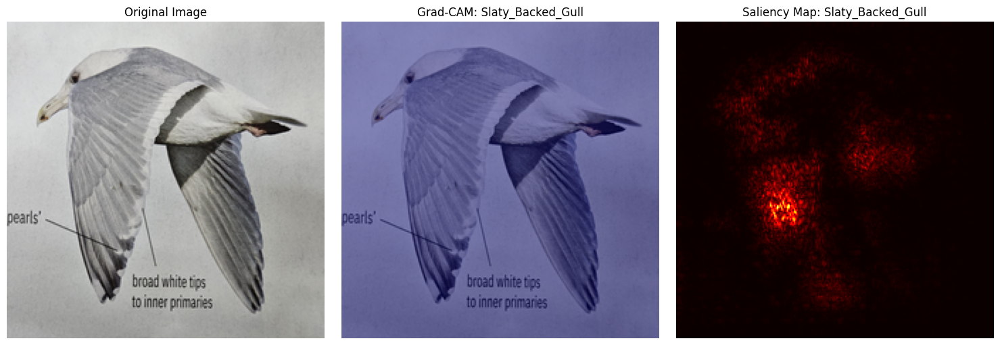

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241203_010647.jpg


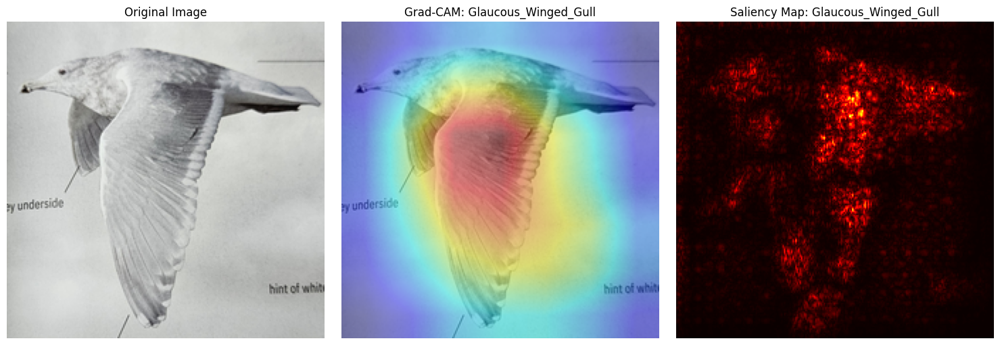

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_141028(1).jpg


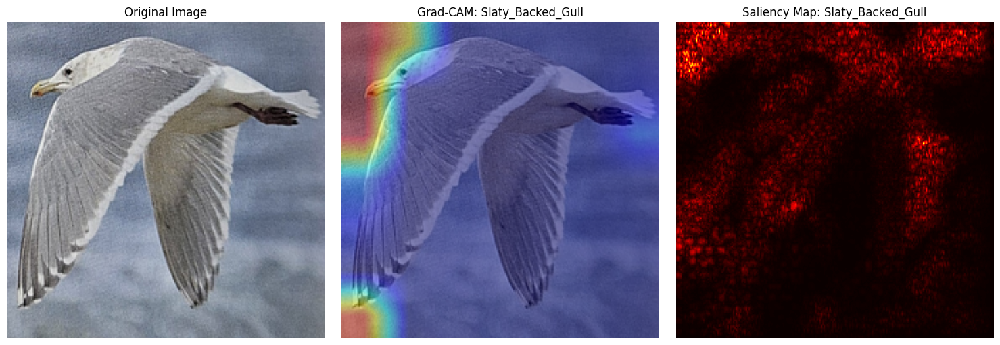

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_140935.jpg


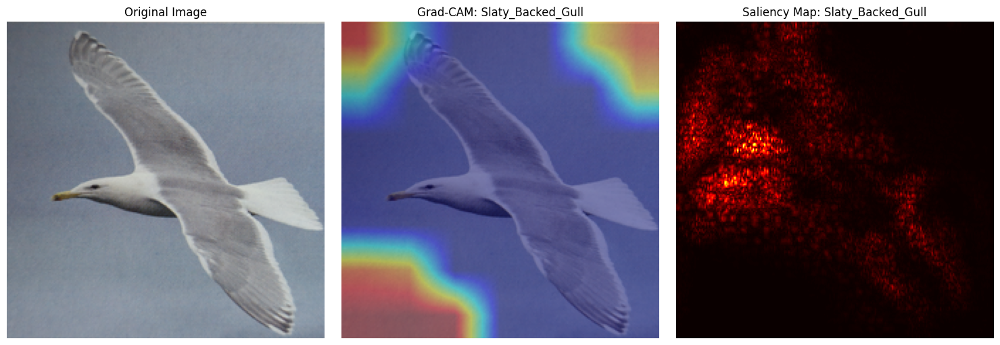

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_140922.jpg


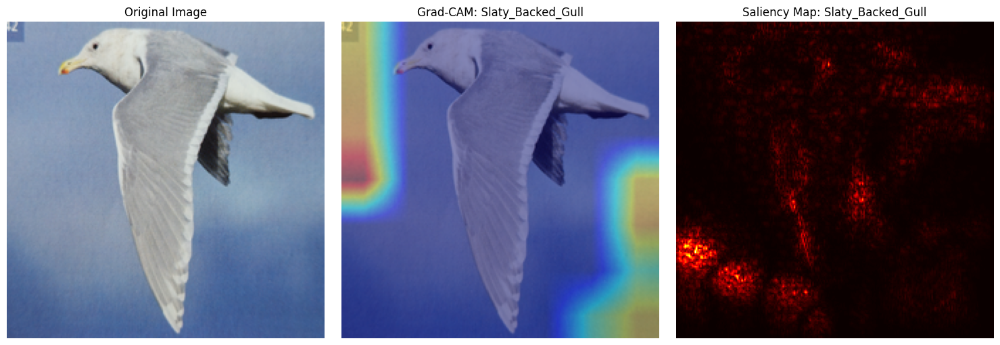

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_170956.jpg


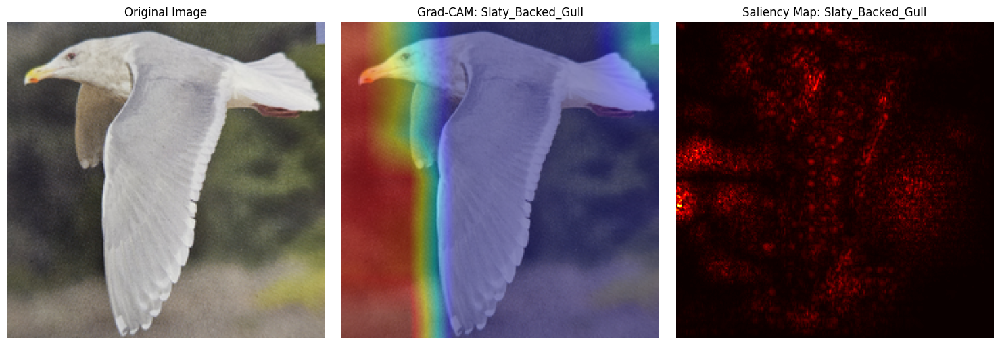

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_171004.jpg


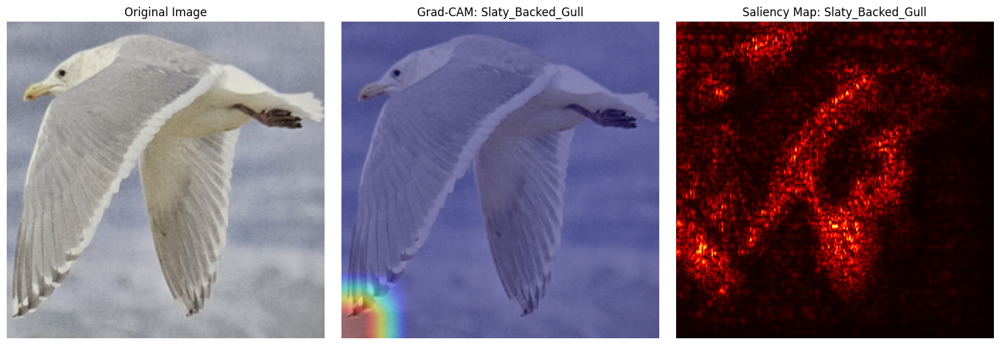

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_171110.jpg


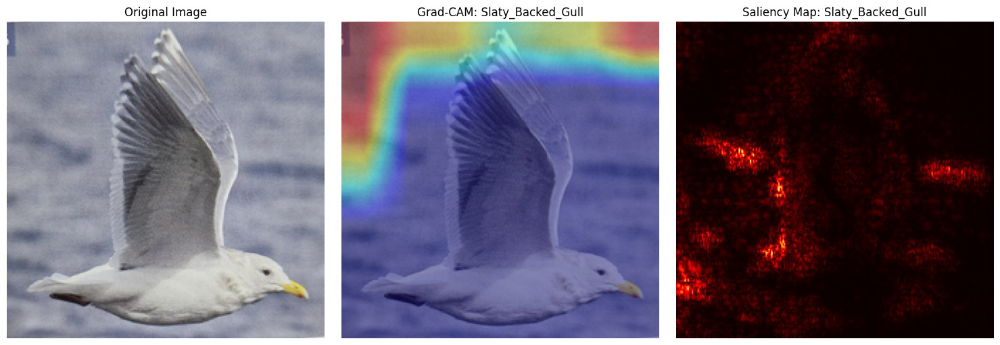

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141619.jpg


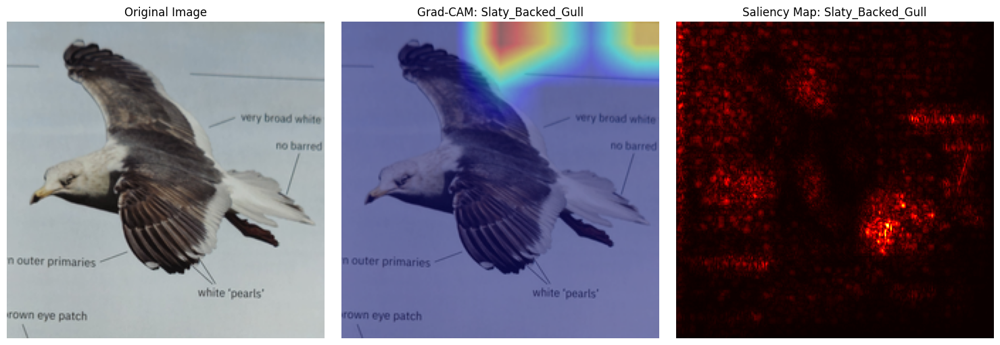

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141608.jpg


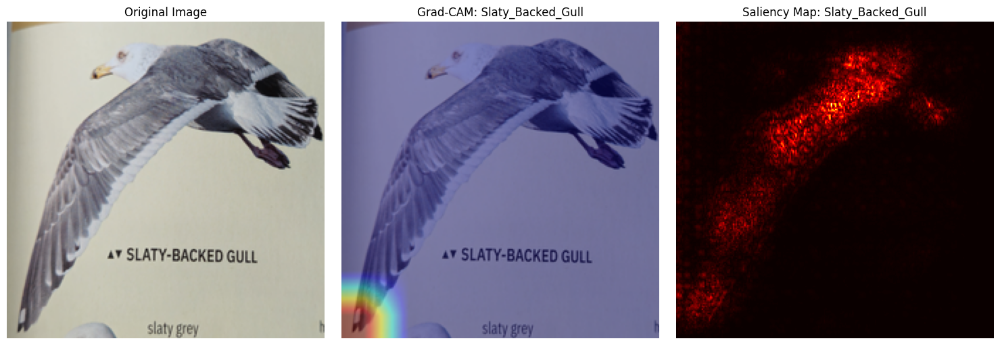

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141506.jpg


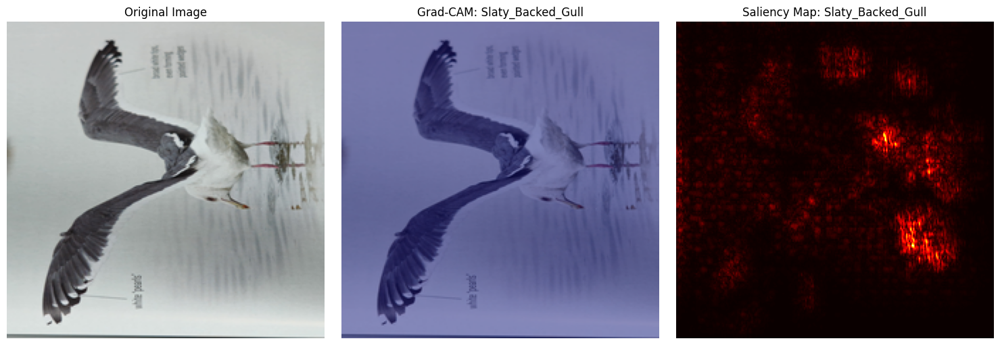

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141028(1).jpg


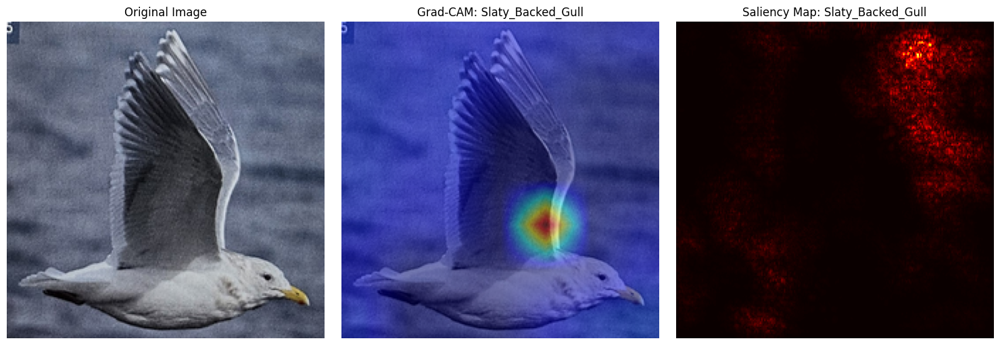

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170328.jpg


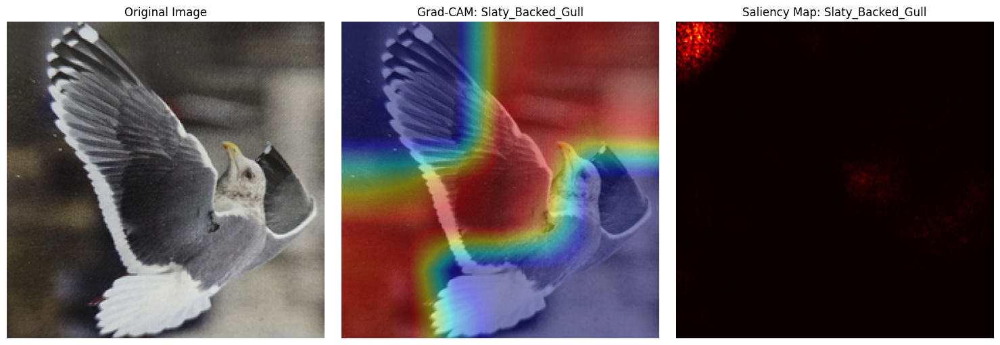

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170332.jpg


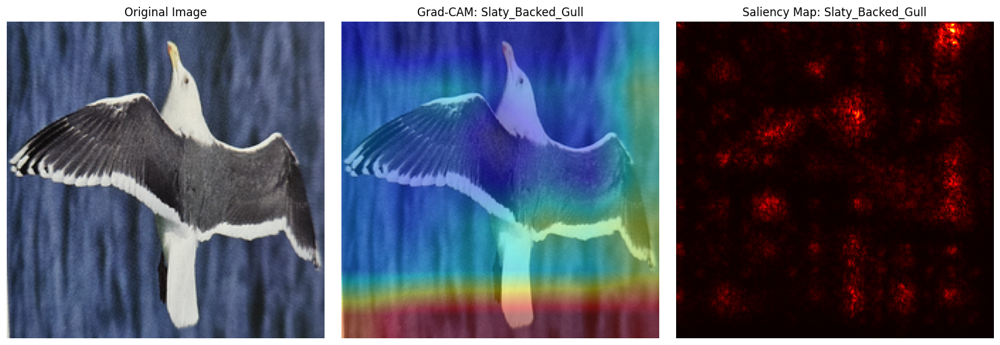

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170314.jpg


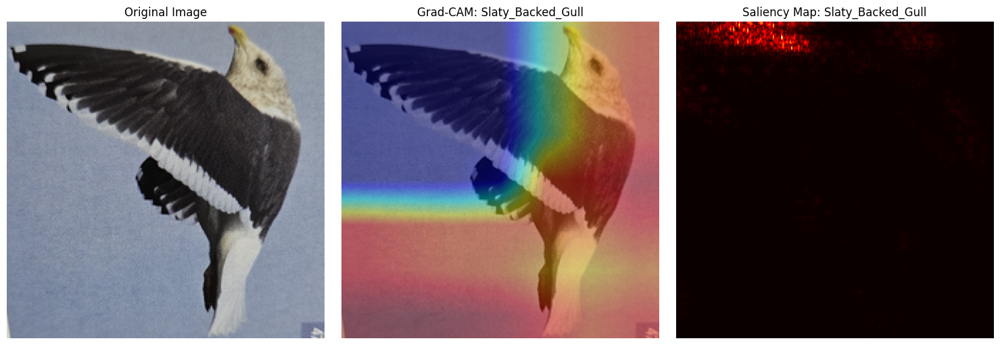

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170322.jpg


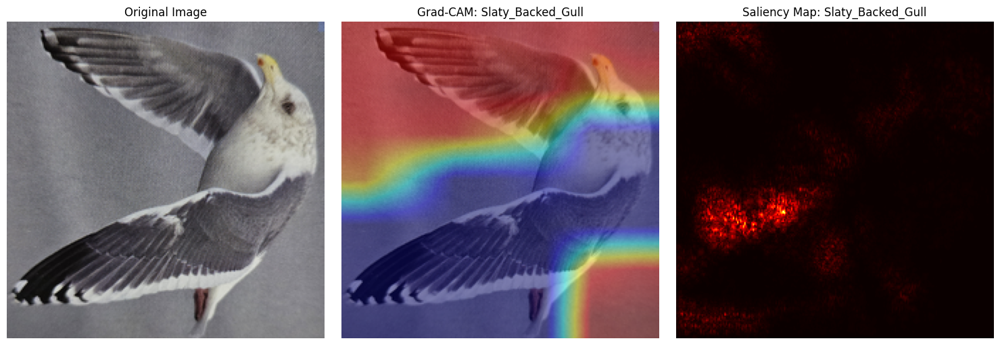

In [12]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define model path and dataset path
checkpoint_path = '/content/drive/My Drive/FYP/ResNetHQ2/20241208/final_model.pth'
test_folder_path = '/content/drive/My Drive/FYP/BOOK_IMAGES_GULL'  # Replace with your test folder path

# Load the Pretrained ResNet50 model
class PretrainedResNet50(nn.Module):
    def __init__(self):
        super(PretrainedResNet50, self).__init__()
        self.resnet = models.resnet50(pretrained=True)
        # Modify the final layer for binary classification (2 classes)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Linear(num_ftrs, 2)  # Binary classification
    def forward(self, x):
        return self.resnet(x)

# Load the trained ResNet model
model = PretrainedResNet50()
model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))
model.eval()

# Define class names as per your dataset
class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']  # Adjust based on your class order

# Define image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet expects 224x224 input size
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet normalization
])

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply transformations
    image = image.unsqueeze(0)  # Add batch dimension
    return image

# Grad-CAM implementation
def generate_gradcam(model, image_tensor, target_layer):
    model.eval()
    features = []
    grads = []

    # Hook functions to capture features and gradients
    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks to the target layer
    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    # Backward pass to get gradients
    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    # Process gradients and feature maps
    gradient = grads[0].cpu().data.numpy()[0]
    feature_map = features[0].cpu().data.numpy()[0]

    # Calculate Grad-CAM
    weights = np.mean(gradient, axis=(1, 2))  # Global average pooling of gradients
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)  # ReLU to remove negative values
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))  # Resize to match image dimensions
    cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))  # Normalize between 0 and 1
    cam = np.clip(cam, 0, 1)  # Make sure values are within [0, 1]
    return cam, predicted_class_idx


# Saliency Map implementation
def generate_saliency_map(model, image_tensor):
    image_tensor.requires_grad_()
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    # Backward pass to calculate gradients
    model.zero_grad()
    output[0, predicted_class_idx].backward()

    # Calculate saliency
    saliency = image_tensor.grad.data.abs()
    saliency, _ = torch.max(saliency, dim=1)  # Take max across channels
    saliency = saliency.squeeze().cpu().numpy()

    # Normalize for visualization
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min())
    return saliency, predicted_class_idx

# Function to visualize results
def visualize_results(image_path, gradcam, saliency, predicted_class):
    original_image = Image.open(image_path).resize((224, 224), Image.LANCZOS)
    original_image = np.array(original_image)

    # Grad-CAM heatmap overlay
    heatmap = cv2.applyColorMap(np.uint8(255 * gradcam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    gradcam_image = np.clip(0.4 * heatmap + 0.6 * original_image, 0, 255).astype(np.uint8)

    # Plot images
    plt.figure(figsize=(15, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(original_image)
    plt.axis('off')

    # Grad-CAM
    plt.subplot(1, 3, 2)
    plt.title(f"Grad-CAM: {class_names[predicted_class]}")
    plt.imshow(gradcam_image)
    plt.axis('off')

    # Saliency Map
    plt.subplot(1, 3, 3)
    plt.title(f"Saliency Map: {class_names[predicted_class]}")
    plt.imshow(saliency, cmap='hot')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Process all images in the test folder
def process_test_folder(test_folder_path):
    target_layer = model.resnet.layer4[2].conv3  # Targeting a layer from ResNet for Grad-CAM (can be adjusted)
    for root, _, files in os.walk(test_folder_path):
        for file in files:
            image_path = os.path.join(root, file)
            print(f"Processing: {image_path}")

            # Preprocess the image
            image_tensor = preprocess_image(image_path)

            # Generate Grad-CAM and Saliency Map
            gradcam, predicted_class_idx_cam = generate_gradcam(model, image_tensor, target_layer)
            saliency, predicted_class_idx_sal = generate_saliency_map(model, image_tensor)

            # Ensure predictions from both methods match
            assert predicted_class_idx_cam == predicted_class_idx_sal, "Predicted class mismatch!"

            # Visualize results
            visualize_results(image_path, gradcam, saliency, predicted_class_idx_cam)

# Run the combined implementation on all images in the test folder
process_test_folder(test_folder_path)
